# PINN de advección en dimensión alta: PCA de coordenadas de entrada

**Pregunta.** ¿Reducir con PCA la dimensión de las coordenadas de entrada puede mantener la precisión física y el tiempo de entrenamiento al aumentar la dimensión ambiental?

Este benchmark usa la ecuación de advección en \(\mathbb R^d\), con una solución analítica que depende de dos direcciones latentes. Se compara la PINN base con PCA de entrada al 99% para \(d=5,10,20\).

## Problema y diseño experimental

La solución exacta es

\[u(x,t)=\sin\!ig(\pi(q_1^	op x-t)ig)+0.5\cos\!ig(\pi(q_2^	op x-0.5t)ig),\]

donde \(q_1,q_2\) son los primeros vectores propios de la covarianza de las coordenadas. La velocidad es \(v=q_1+0.5q_2\), así que satisface \(u_t+v^	op
abla_xu=0\).

- Diez semillas y 2000 pasos por modelo y dimensión.
- Coordenadas gaussianas con autovalores de covarianza que decaen geométricamente; la solución depende de las dos direcciones de mayor varianza.
- PCA se ajusta solamente con coordenadas de entrenamiento. En la PINN reducida, `x` se proyecta linealmente y JAX autodiferencia a través de esa proyección para calcular el gradiente respecto de las coordenadas originales.
- Los modelos comparten particiones temporales, datos supervisados, condiciones iniciales y puntos de colocación. Los tamaños de red se emparejan para mantener los parámetros dentro de 5%.

**Alcance:** esto prueba PCA en las coordenadas de entrada, una variante distinta del PCA espacial de snapshots usado en los experimentos de advección 1D. Además, es un caso favorable en el que las direcciones de mayor varianza coinciden con las que determinan la solución; no representa todos los problemas de alta dimensión.

In [ ]:
from pathlib import Path
import json
from IPython.display import display, HTML, SVG

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RUN_DIR = ROOT / "results/high_dimensional_advection/input_pca_vs_base/aligned_low_intrinsic_advection_d5_10_20_10_seeds_v1"
RESULT = json.loads((RUN_DIR / "summary.json").read_text(encoding="utf-8"))
SUMMARY = RESULT["summary_by_dimension"]
DIMS = sorted(int(d) for d in SUMMARY)


def html_table(headers, rows):
    head = "".join(f"<th>{h}</th>" for h in headers)
    body = "".join("<tr>" + "".join(f"<td>{v}</td>" for v in row) + "</tr>" for row in rows)
    return f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"


def stat(s, metric, digits=4):
    v = s[metric]
    return f"{v['mean']:.{digits}g} ± {v['std']:.{digits}g}"


## Resultados por dimensión

Medias ± desviaciones estándar entre las diez semillas. La columna de dimensión compara el número de entradas del MLP (coordenadas más tiempo) antes y después de PCA.

In [1]:
rows = []
for d in DIMS:
    base, pca = SUMMARY[str(d)]["PINN base"], SUMMARY[str(d)]["PCA input 99%"]
    rows.append([d, f"{d+1} → {pca['k']['mean']+1:.0f}", f"{pca['k']['mean']:.0f}", f"{100*pca['retained_variance']['mean']:.3f}%", stat(base,"test_relative_l2"), stat(pca,"test_relative_l2"), stat(base,"test_pde_residual_rms"), stat(pca,"test_pde_residual_rms"), stat(base,"pipeline_seconds",3), stat(pca,"pipeline_seconds",3)])
display(HTML(html_table(["d", "Dimensión base → PCA", "k", "Varianza", "Error L2 base", "Error L2 PCA", "Residuo base", "Residuo PCA", "Pipeline base (s)", "Pipeline PCA (s)"], rows)))


d,Dimensión de entrada base → PCA,k PCA,Varianza,Error L2 base,Error L2 PCA,Residuo base,Residuo PCA,Pipeline base (s),Pipeline PCA (s)
5,6 → 4,3,99.250%,0.1168 ± 0.04799,0.1272 ± 0.05325,0.01567 ± 0.003325,0.01402 ± 0.002353,2.5 ± 0.0235,2.46 ± 0.0229
10,11 → 4,3,99.198%,0.128 ± 0.04627,0.1145 ± 0.04347,0.01757 ± 0.002993,0.01324 ± 0.003228,2.57 ± 0.0422,2.6 ± 0.0375
20,21 → 4,3,99.218%,0.1004 ± 0.03561,0.1069 ± 0.02361,0.01654 ± 0.004817,0.0142 ± 0.004385,2.68 ± 0.145,2.75 ± 0.115


## Diferencias pareadas PCA − base

Los conteos indican en cuántas de las diez semillas PCA obtuvo un valor menor. En el tiempo, un valor menor significa que el pipeline PCA fue más rápido.

In [1]:
rows = []
for d in DIMS:
    m = RESULT["paired_differences_PCA_minus_base"][str(d)]
    e, p, t = (m[key] for key in ("test_relative_l2", "test_pde_residual_rms", "pipeline_seconds"))
    rows.append([d, f"{e['PCA_minus_base_mean']:+.4f}", f"{e['PCA_better_count']}/10", f"{p['PCA_minus_base_mean']:+.4f}", f"{p['PCA_better_count']}/10", f"{t['PCA_minus_base_mean']:+.4f}", f"{t['PCA_better_count']}/10"])
display(HTML(html_table(["d", "Δ error L2", "Semillas mejor L2", "Δ residuo PDE", "Semillas mejor residuo", "Δ tiempo (s)", "Semillas más rápidas"], rows)))


d,Δ error L2 medio,Semillas mejor L2,Δ residuo medio,Semillas mejor residuo,Δ tiempo medio (s),Semillas más rápidas
5,+0.0104,4/10,-0.0017,8/10,-0.0427,9/10
10,-0.0135,9/10,-0.0043,8/10,+0.0288,1/10
20,+0.0065,4/10,-0.0023,7/10,+0.0653,1/10


## Escalamiento

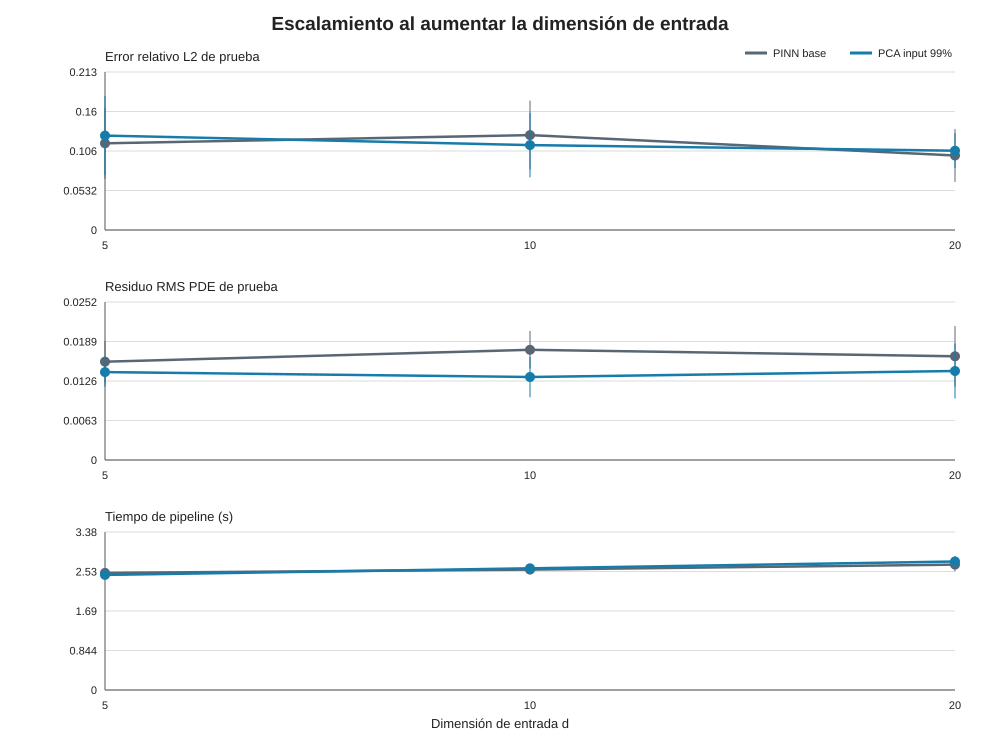

In [1]:
display(SVG(filename=str(RUN_DIR / "dimension_scaling.svg")))

## Trayectorias de validación por dimensión

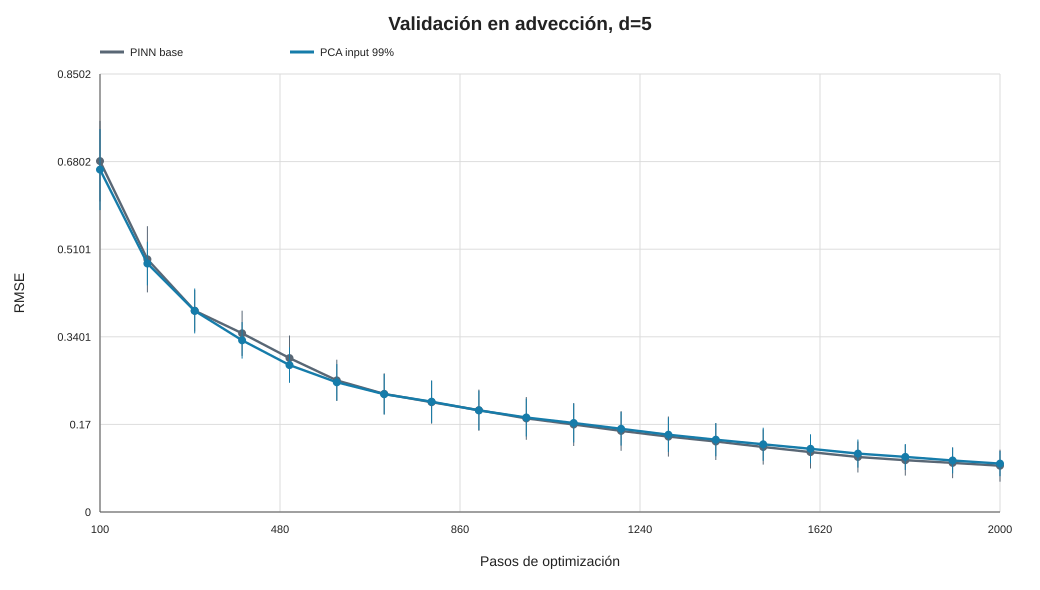

In [1]:
display(SVG(filename=str(RUN_DIR / "validation_d5.svg")))

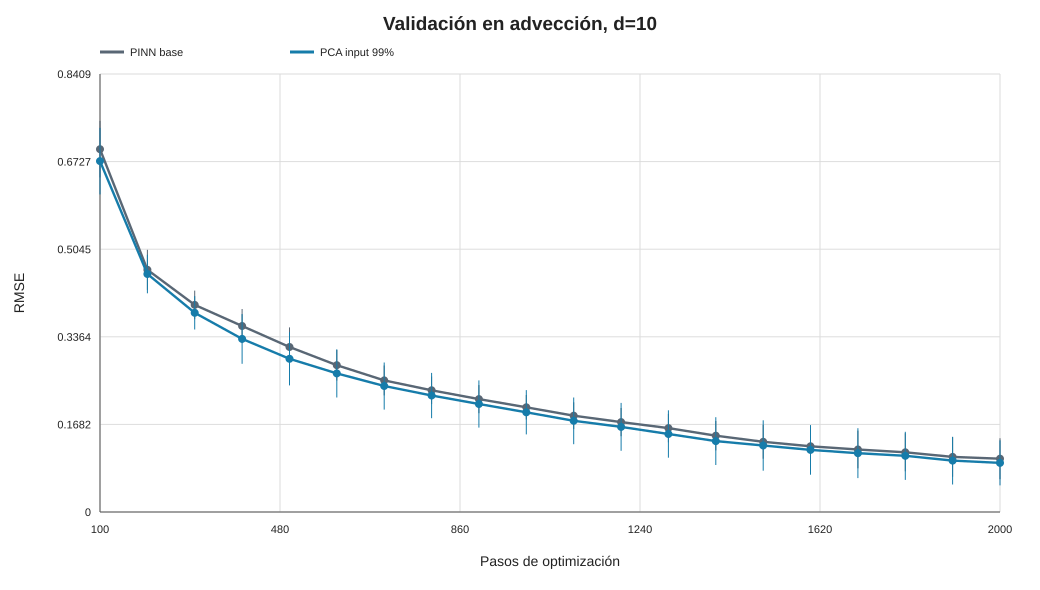

In [1]:
display(SVG(filename=str(RUN_DIR / "validation_d10.svg")))

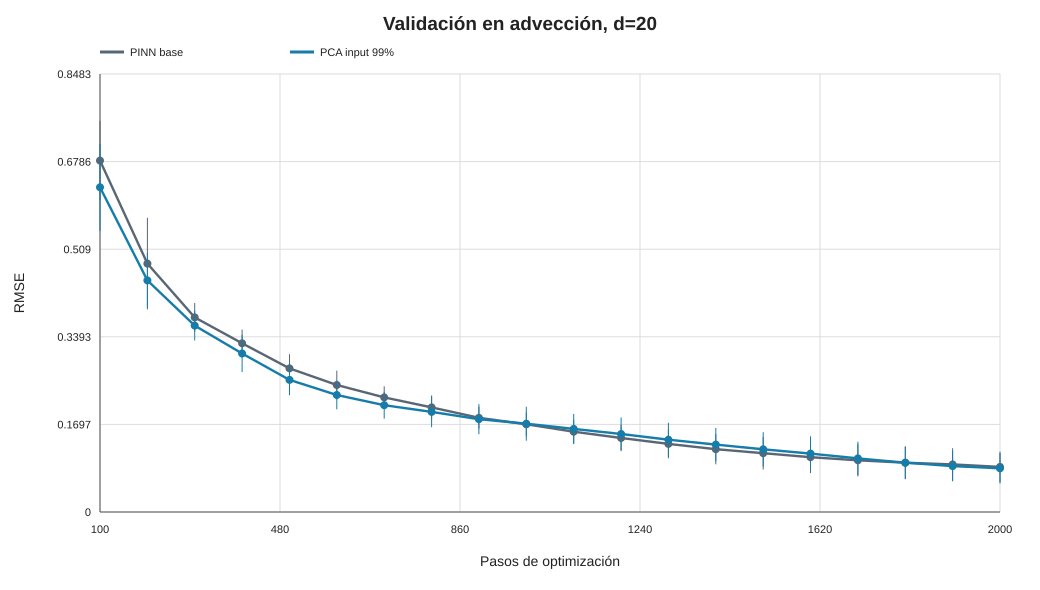

In [1]:
display(SVG(filename=str(RUN_DIR / "validation_d20.svg")))

## Lectura del benchmark

- PCA retuvo tres componentes en las diez semillas para cada dimensión, conservando aproximadamente 99,2% de varianza. El MLP pasó de `d+1` entradas a cuatro (tres scores PCA más tiempo).
- El error L2 no mejoró de forma consistente: PCA fue mejor en 9/10 semillas para `d=10`, pero solo en 4/10 para `d=5` y `d=20`.
- El residuo PDE medio fue menor con PCA en las tres dimensiones, aunque la diferencia varía por dimensión y dispersión entre semillas.
- No se observó una reducción estable del pipeline: PCA fue apenas más rápido en `d=5` y ligeramente más lento en `d=10` y `d=20`. Los tiempos son de esta máquina y presupuesto.

**Conclusión inicial:** aun en este caso alineado y de baja dimensión intrínseca, la reducción de entradas por PCA no produjo una aceleración medible consistente bajo esta arquitectura y presupuesto. La prueba no demuestra que PCA falle en todos los problemas de alta dimensión; el siguiente control debería desalinear varianza y relevancia física o aumentar sustancialmente `d`.

## Reproducibilidad

- Configuración: `configs/high_dim_advection.json`
- Ejecutor: `scripts/run_high_dim_advection.py`
- Resultados: `results/high_dimensional_advection/input_pca_vs_base/aligned_low_intrinsic_advection_d5_10_20_10_seeds_v1/`

```powershell
.venv-jax-latest\Scripts\python.exe scripts\run_high_dim_advection.py --config configs\high_dim_advection.json
```
